# Colour-Invariant Saree Design Recognition
**Pretrained ResNet34 + Triplet Loss + strong colour augmentation** (PyTorch)

```
Image → Colour augmentation → Pretrained ResNet34 → 256-D embedding → L2 normalisation

Training : Anchor (design A, colour 1) + Positive (design A, colour 2) + Negative (design B, SAME colour 1) → Triplet loss
Inference: Query embedding → cosine similarity with gallery → Top-K designs   |   pair → cosine ≥ τ → same design
```

### Approach note (489 chars)
> We use a pretrained ImageNet ResNet34 as a shared embedding encoder. Images are resized and color-augmented using brightness, saturation, hue and grayscale transformations. A 256-D normalized embedding is learned with Triplet Loss using same-design different-colour positives and different-design negatives. PK batches deliberately share colourways across designs to create hard same-colour negatives. Retrieval uses cosine similarity, with validation-selected thresholds for verification.

**Kaggle:** add the dataset `div456/indian-saree-patterns`, and add the DeepLure corpus as a **private** dataset (it is vendor-proprietary, so do not make it public). Turn on the GPU (T4 or P100) and choose Run All. A full run takes about 15-20 min.

### Results of this run (CPU budget: 15 epochs, P=16, K=4; test = 189 unseen designs)
| Method | R@1 | R@5 | mAP | ROC-AUC | AUC same-palette | EER |
|---|---|---|---|---|---|---|
| RGB colour histogram | 0.011 | 0.048 | 0.026 | 0.421 | 0.000 | 0.541 |
| ImageNet ResNet34 (no training) | 0.262 | 0.482 | 0.234 | 0.686 | 0.515 | 0.353 |
| **Ours: ResNet34 + triplet + colourways** | **0.476** | **0.743** | **0.408** | **0.900** | **0.853** | **0.194** |

Per source (R@1): Roboflow 0.98, DeepLure 0.40 (out-of-domain, never used for training or tuning). 21.4 M params, 7.3 GFLOPs, 256-D embedding (512 B fp16).
On a GPU the notebook automatically uses the full budget (30 epochs, P=32).

## 01. Imports + GPU setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

import os, re, glob, math, time, json, random
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

CFG = dict(
    cache_size=288,
    img_size=224,
    dedup_hamming=6,
    embed_dim=256,
    P=32, K=4,
    epochs=30, iters_per_epoch=40,
    lr_backbone=1e-4, lr_head=1e-3, weight_decay=1e-4, warmup_epochs=1,
    margin=0.2,
    shared_palette_prob=0.75,
    save_every=2,
    kmeans_k=5,
    seed=42, eval_seed=1234,
    num_workers=2 if os.path.exists("/kaggle") else 0,
)
if device.type == "cpu":
    CFG.update(P=16, epochs=15, iters_per_epoch=25, save_every=3)
SMOKE = False
if SMOKE:
    CFG.update(P=4, K=2, epochs=2, iters_per_epoch=2, save_every=1)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["seed"])
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)

torch 2.8.0+cpu | torchvision 0.23.0+cpu | device: cpu


## 02. Dataset load
Two sources: the Kaggle *Indian Saree Patterns* dataset (a Roboflow export: `train/valid/test/<style>/`) and the unlabelled DeepLure corpus (`h_img_*.jpg`, `img_*.jpg`). Paths are found automatically.

In [3]:
DATA_DIR = "/kaggle/input" if os.path.exists("/kaggle/input") else "E:/assignment"

def find_dir(test):
    for d, sub, files in os.walk(DATA_DIR):
        if test(sub, files):
            return d

ROBOFLOW_ROOT = find_dir(lambda sub, files: {"train", "valid", "test"} <= set(sub))
DEEPLURE_ROOT = find_dir(lambda sub, files: any(f.startswith("h_img_") for f in files))
print("Roboflow :", ROBOFLOW_ROOT); print("DeepLure :", DEEPLURE_ROOT)

EXT = (".jpg", ".jpeg", ".png", ".webp")
rows = []
for split in ["train", "valid", "test"]:
    for style in sorted(os.listdir(os.path.join(ROBOFLOW_ROOT, split))):
        for f in sorted(os.listdir(os.path.join(ROBOFLOW_ROOT, split, style))):
            if f.lower().endswith(EXT):
                rows.append(dict(path=os.path.join(ROBOFLOW_ROOT, split, style, f),
                                 source="roboflow", orig_split=split, style=style))
if DEEPLURE_ROOT:
    for f in sorted(os.listdir(DEEPLURE_ROOT)):
        if f.lower().endswith(EXT):
            rows.append(dict(path=os.path.join(DEEPLURE_ROOT, f), source="deeplure",
                             orig_split="test", style="unknown"))
df = pd.DataFrame(rows)
print(len(df), "images")
df.groupby(["source", "orig_split", "style"]).size().unstack(fill_value=0)

Roboflow : E:/assignment\archive (1)
DeepLure : E:/assignment\handloom_sarees-20261001T144025Z-1-001\handloom_sarees
1633 images


style                Banarasi  Bandhani  Ikat  Pichwai  unknown
source   orig_split                                            
deeplure test               0         0     0        0      165
roboflow test              14        15    13       18        0
         train            432       279   303      279        0
         valid             43        22    26       24        0

## 03. Dataset inspection / cleaning
What the inspection found:
* The Roboflow export saves every source photo **3 times** with salt-and-pepper noise (`<name>_jpg.rf.<hash>.jpg`). The 3 files are one design, not three.
* The same photo also appears under **different file names**, sometimes in different original splits. A perceptual hash (dHash, 64-bit, computed on luminance so recoloured copies still collide) finds these. Hamming distance ≤ 6 was checked by eye: pairs up to about 7 are true duplicates, and 8 starts giving false matches.

All images are centre-cropped to a square and cached in RAM at 288×288.

In [5]:
def load_square(path, size=CFG["cache_size"]):
    im = Image.open(path).convert("RGB")
    w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((size, size), Image.BICUBIC)
    return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1).contiguous()

with ThreadPoolExecutor(8) as ex:
    sizes = list(ex.map(lambda p: Image.open(p).size, df.path))
    imgs = list(ex.map(load_square, df.path))
CACHE = dict(zip(df.path, imgs))
df["w"], df["h"] = [s[0] for s in sizes], [s[1] for s in sizes]
print(df.groupby("source")[["w", "h"]].describe().T.round(0))

fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, (_, r) in zip(axs.flat, pd.concat([df[df.source == "roboflow"].sample(8, random_state=0),
                                           df[df.source == "deeplure"].sample(8, random_state=0)]).iterrows()):
    ax.imshow(CACHE[r.path].permute(1, 2, 0)); ax.set_title(f"{r.source}/{r.style}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()



source   deeplure  roboflow
w count     165.0    1468.0
  mean      815.0     640.0
  std       329.0       0.0
  min       226.0     640.0
  25%       590.0     640.0
  50%       662.0     640.0
  75%       986.0     640.0
  max      1512.0     640.0
h count     165.0    1468.0
  mean      821.0     640.0
  std       328.0       0.0
  min       226.0     640.0
  25%       589.0     640.0
  50%       662.0     640.0
  75%       986.0     640.0
  max      1512.0     640.0


[figure removed from the public copy: it shows proprietary DeepLure images - it renders when you run the notebook]


merged by file name: 862 | extra merges by dHash: 199 | unique designs: 572


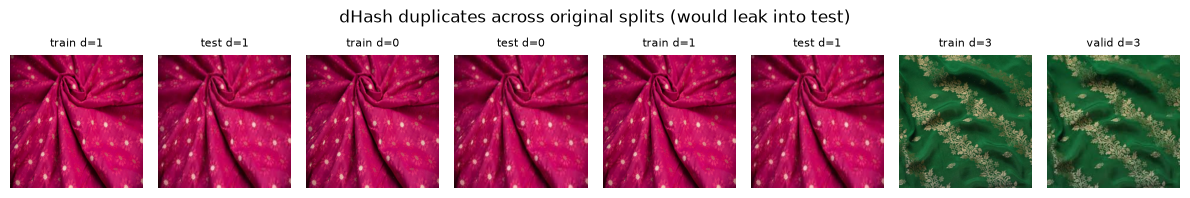

In [7]:
def dhash(img_u8):
    g = Image.fromarray(img_u8.permute(1, 2, 0).numpy()).convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

H = np.stack([dhash(CACHE[p]) for p in df.path]).astype(np.float32) * 2 - 1
HAM = (64 - H @ H.T) / 2

parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b): parent[find(a)] = find(b)

df["stem"] = [re.sub(r"\.rf\.[0-9a-f]+\.\w+$", "", os.path.basename(p)) for p in df.path]
first = {}
for i, key in enumerate(zip(df["style"], df["stem"], df["source"])):
    if key in first: union(i, first[key])
    else: first[key] = i
n_name = len(df) - len({find(i) for i in range(len(df))})
ii, jj = np.where(np.triu(HAM <= CFG["dedup_hamming"], 1))
dup_pairs = [(i, j) for i, j in zip(ii, jj) if find(i) != find(j)]
n_hash = 0
for i, j in dup_pairs:
    if find(i) != find(j): union(i, j); n_hash += 1
df["group"] = [find(i) for i in range(len(df))]
print(f"merged by file name: {n_name} | extra merges by dHash: {n_hash} | unique designs: {df.group.nunique()}")

show = [(i, j) for i, j in dup_pairs if df.orig_split[i] != df.orig_split[j]][:4] or dup_pairs[:4]
if show:
    fig, axs = plt.subplots(1, 2 * len(show), figsize=(3 * len(show), 2))
    for k, (i, j) in enumerate(show):
        for a, idx in zip(axs[2 * k:2 * k + 2], (i, j)):
            a.imshow(CACHE[df.path[idx]].permute(1, 2, 0)); a.axis("off")
            a.set_title(f"{df.orig_split[idx]} d={int(HAM[i, j])}", fontsize=8)
    plt.suptitle("dHash duplicates across original splits (would leak into test)"); plt.tight_layout(); plt.show()

## 04. design_id / colourway_id CSV
**No dataset has real "same design, different colour" labels**, so the label definitions are:
* `design_id` is one duplicate group, meaning one physical source photo of one saree design.
* `colourway_id` is `c0` (the original colours) for every real file. Other colourways are **generated**: random ones during training (step 06/08), and fixed-seed ones at evaluation, which are written to `eval_pairs_*.csv` in step 12 with their own `colourway_id`.

In [9]:
df["design_id"] = df.group.map({g: f"D{k:04d}" for k, g in enumerate(sorted(df.group.unique()))})
df["colourway_id"] = "c0"
meta = df[["path", "source", "orig_split", "style", "design_id", "colourway_id"]]
meta.to_csv(f"{OUT}/metadata.csv", index=False)
print(meta.design_id.value_counts().describe().round(2))
meta.head()

count    572.00
mean       2.85
std        1.83
min        1.00
25%        1.00
50%        3.00
75%        4.00
max        6.00
Name: count, dtype: float64


,path,source,orig_split,style,design_id,colourway_id
0,E:/assignment\archive (1)\train\Banarasi\0X2A9...,roboflow,train,Banarasi,D0020,c0
1,E:/assignment\archive (1)\train\Banarasi\0X2A9...,roboflow,train,Banarasi,D0020,c0
2,E:/assignment\archive (1)\train\Banarasi\0X2A9...,roboflow,train,Banarasi,D0020,c0
3,E:/assignment\archive (1)\train\Banarasi\0X2A9...,roboflow,train,Banarasi,D0068,c0
4,E:/assignment\archive (1)\train\Banarasi\0X2A9...,roboflow,train,Banarasi,D0068,c0


## 05. Train / Validation / Test split
The split is made **by design** and follows the original folders, with one fix: a design whose duplicates were found in several splits goes to **train**, so every val and test design is unseen.
* **train**: Roboflow `train` designs
* **val**: Roboflow `valid` designs, used to pick the checkpoint and the verification threshold
* **test**: Roboflow `test` plus **all of DeepLure** (out-of-domain handloom close-ups, never used for training or tuning)

In [11]:
rank = {"train": 0, "valid": 1, "test": 2}
grp_split = df.groupby("design_id").orig_split.agg(lambda s: min(s, key=rank.get))
moved = (df.groupby("design_id").orig_split.nunique() > 1).sum()
df["split"] = df.design_id.map(grp_split).map({"train": "train", "valid": "val", "test": "test"})
meta = df[["path", "source", "orig_split", "split", "style", "design_id", "colourway_id"]]
meta.to_csv(f"{OUT}/metadata.csv", index=False)
print("designs moved to train because they straddled splits:", moved)
summary = df.groupby(["split", "source"]).agg(images=("path", "size"), designs=("design_id", "nunique"))
assert not set(df[df.split == "train"].design_id) & set(df[df.split != "train"].design_id)
summary


designs moved to train because they straddled splits: 87


images  designs
split source                   
test  deeplure     165      164
      roboflow      27       25
train roboflow    1376      330
val   roboflow      65       53

In [13]:
def design_map(split, source=None):
    d = df[(df.split == split) & ((df.source == source) if source else True)].sort_values("path")
    return {k: g.to_dict("records") for k, g in d.groupby("design_id")}
TRAIN, VAL, TEST = design_map("train"), design_map("val"), design_map("test")
if SMOKE:
    VAL = dict(list(VAL.items())[:6])
    TEST = dict(list(design_map("test", "roboflow").items())[:3] + list(design_map("test", "deeplure").items())[:3])
print(len(TRAIN), "train /", len(VAL), "val /", len(TEST), "test designs")


330 train / 53 val / 189 test designs


## 06. Data augmentation
**Geometry** (CPU, per view): random resized crop (25-100% of the area), horizontal and vertical flips, 90° rotation, mild perspective, blur.

**Colour, used in training** (GPU, batched). Each op keeps the motif's structure and replaces the colours:
| op | what it does |
|---|---|
| hue rotation | rotate hue in YIQ space by a random angle, and scale saturation |
| channel swap | permute R, G, B |
| gradient map | luminance → random 2-5 colour palette with monotone brightness (the classic way a textile colourway is made) |
| grayscale / invert | remove colour entirely, or swap light and dark (common for sarees: light motif on dark ground and vice versa) |
| + jitter | brightness and contrast on top of every op |

**Colour, used only in evaluation:** a **k-means palette swap**. The image is clustered into 5 dominant colours, each one is replaced by a new dye colour, and the per-pixel shading residual is kept. This operator is **never used in training**, so test scores show whether colour invariance *generalises* rather than whether the model memorised its own augmentations.

In [15]:
train_geo = T.Compose([
    T.RandomResizedCrop(CFG["img_size"], scale=(0.25, 1.0), ratio=(0.75, 1.333), antialias=True),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomApply([T.RandomRotation(degrees=(90, 90))], p=0.5),
    T.RandomApply([T.RandomPerspective(distortion_scale=0.2, p=1.0)], p=0.3),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    T.ToDtype(torch.float32, scale=True),
])
def eval_resize(img_u8):
    return T.functional.resize(img_u8, [CFG["img_size"]] * 2, antialias=True).float() / 255.0

LUMA = torch.tensor([0.299, 0.587, 0.114])
PERMS = torch.tensor([[0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]])
def luminance(x): return (x * LUMA.to(x).view(1, 3, 1, 1)).sum(1, keepdim=True)

def hue_rotate(x, theta, sat):
    rgb2yiq = torch.tensor([[0.299, 0.587, 0.114], [0.596, -0.274, -0.322], [0.211, -0.523, 0.312]], device=x.device)
    c, s = torch.cos(theta) * sat, torch.sin(theta) * sat
    R = torch.zeros(len(x), 3, 3, device=x.device); R[:, 0, 0] = 1
    R[:, 1, 1], R[:, 1, 2], R[:, 2, 1], R[:, 2, 2] = c, -s, s, c
    M = torch.linalg.inv(rgb2yiq) @ R @ rgb2yiq
    return torch.einsum("nij,njhw->nihw", M, x).clamp(0, 1)

def gradient_map(x, palette, stops, gamma):
    N, _, Hh, W = x.shape
    l = luminance(x).flatten(1)
    l = ((l - l.amin(1, keepdim=True)) / (l.amax(1, keepdim=True) - l.amin(1, keepdim=True) + 1e-6)) ** gamma[:, None]
    idx = torch.searchsorted(stops.contiguous(), l.contiguous()).clamp(1, stops.shape[1] - 1)
    t0, t1 = stops.gather(1, idx - 1), stops.gather(1, idx)
    w = ((l - t0) / (t1 - t0 + 1e-6)).clamp(0, 1)[..., None]
    c0 = palette.gather(1, (idx - 1)[..., None].expand(-1, -1, 3)); c1 = palette.gather(1, idx[..., None].expand(-1, -1, 3))
    return (c0 * (1 - w) + c1 * w).transpose(1, 2).reshape(N, 3, Hh, W)

OP_PROBS = torch.tensor([0.10, 0.25, 0.15, 0.30, 0.10, 0.10])
def sample_colourways(n, device, M=5):
    k = torch.randint(2, M + 1, (n,))
    pos = torch.arange(M)[None].float() / (k[:, None] - 1).float()
    jit = (torch.rand(n, M) - 0.5) * 0.6 / (k[:, None] - 1).float()
    stops = torch.where(torch.arange(M)[None] < k[:, None] - 1, pos + jit, torch.ones(n, M)); stops[:, 0] = 0
    stops = torch.sort(stops.clamp(0, 1), 1).values
    a = torch.empty(n, 1, 1).uniform_(0.3, 0.6)
    pal = (a * torch.rand(n, M, 3) + (1 - a) * stops[..., None]).clamp(0, 1)
    pal = pal.gather(1, (pal * LUMA).sum(-1).argsort(1)[..., None].expand(-1, -1, 3))
    for i in torch.nonzero(torch.rand(n) < 0.5).flatten().tolist():
        kk = int((stops[i] < 1).sum()) + 1
        pal[i, :kk] = pal[i, :kk].flip(0)
    p = dict(op=torch.multinomial(OP_PROBS, n, replacement=True), theta=torch.rand(n) * 2 * math.pi,
             sat=0.3 + 1.3 * torch.rand(n), perm=torch.randint(0, 5, (n,)), palette=pal, stops=stops,
             gamma=torch.exp(torch.empty(n).uniform_(-0.5, 0.5)),
             bright=torch.empty(n).uniform_(0.75, 1.25), contrast=torch.empty(n).uniform_(0.7, 1.3))
    return {k_: v.to(device) for k_, v in p.items()}

def apply_colourways(x, p):
    N = len(x); sel = lambda i: (p["op"] == i).view(N, 1, 1, 1)
    out = torch.where(sel(1), hue_rotate(x, p["theta"], p["sat"]), x)
    perm = PERMS.to(x.device)[p["perm"]]
    out = torch.where(sel(2), x.gather(1, perm[:, :, None, None].expand_as(x)), out)
    out = torch.where(sel(3), gradient_map(x, p["palette"], p["stops"], p["gamma"]), out)
    out = torch.where(sel(4), luminance(x).expand_as(x), out)
    out = torch.where(sel(5), hue_rotate(1 - x, p["theta"], p["sat"]), out)
    m = out.mean((1, 2, 3), keepdim=True)
    out = ((out - m) * p["contrast"].view(N, 1, 1, 1) + m) * p["bright"].view(N, 1, 1, 1)
    return out.clamp(0, 1)


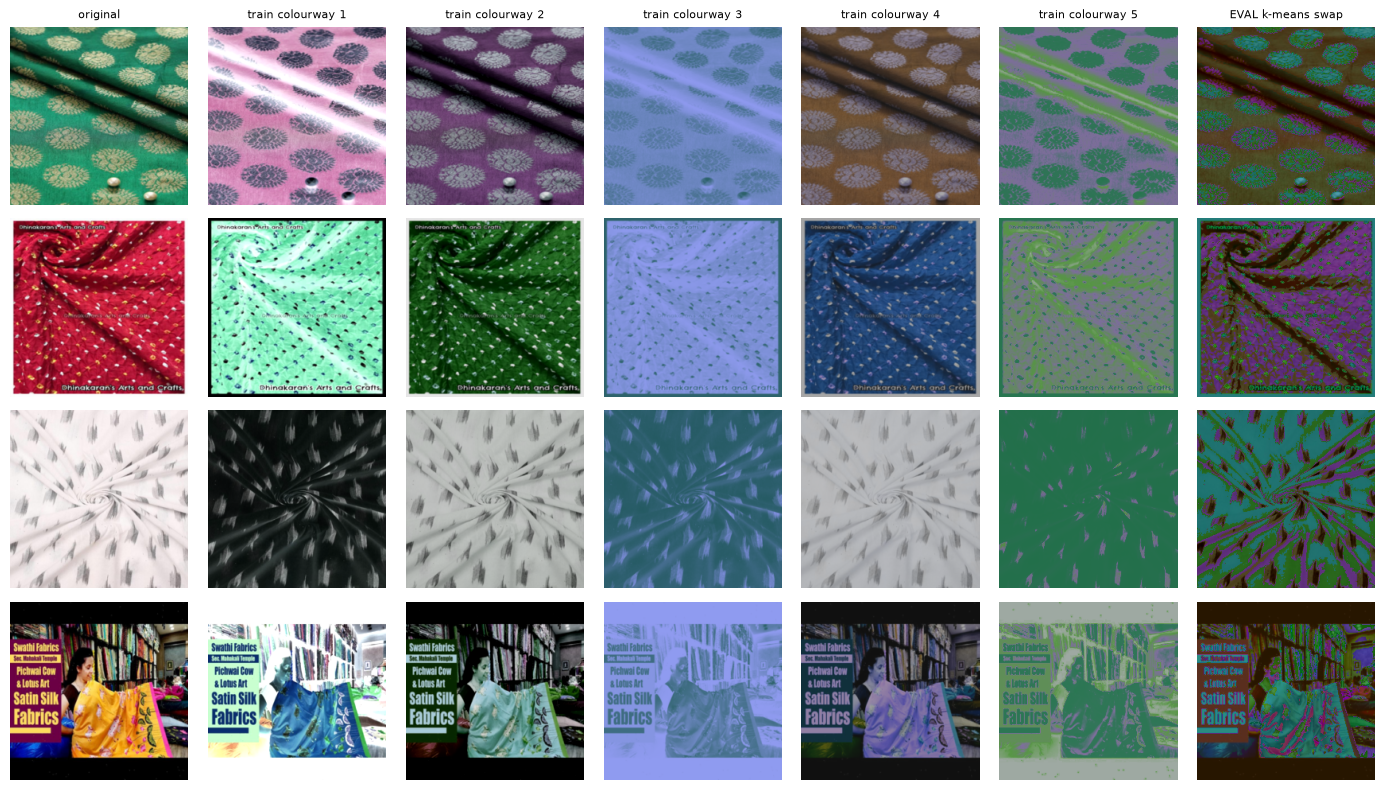

In [17]:
def random_palette(k, g):
    h, s, v = torch.rand(k, generator=g), 0.25 + 0.75 * torch.rand(k, generator=g), 0.15 + 0.85 * torch.rand(k, generator=g)
    i = (h * 6).floor(); f = h * 6 - i; p_, q, t = v * (1 - s), v * (1 - f * s), v * (1 - (1 - f) * s)
    i = i.long()[:, None] % 6
    pick = lambda *c: torch.stack(c, 1).gather(1, i)[:, 0]
    return torch.stack([pick(v, q, p_, p_, t, v), pick(t, v, v, q, p_, p_), pick(p_, p_, t, v, v, q)], 1)

def kmeans_recolour(x, palette, seed, k=CFG["kmeans_k"], keep_residual=0.6, preserve_order=True, iters=8):
    g = torch.Generator().manual_seed(seed)
    pix = x.flatten(1).T
    sub = pix[torch.randperm(len(pix), generator=g)[:4096]]
    c = sub[torch.randperm(len(sub), generator=g)[:k]].clone()
    for _ in range(iters):
        a = torch.cdist(sub, c).argmin(1)
        for j in range(k):
            if (a == j).any(): c[j] = sub[a == j].mean(0)
    a = torch.cdist(pix, c).argmin(1)
    new = palette.clone()
    if preserve_order:
        new = new[torch.argsort((new * LUMA).sum(1))][torch.argsort(torch.argsort((c * LUMA).sum(1)))]
    return (new[a] + keep_residual * (pix - c[a])).T.reshape_as(x).clamp(0, 1)

torch.manual_seed(0)
ex = list(TRAIN.values())[::max(1, len(TRAIN) // 4)][:4]
x = torch.stack([eval_resize(CACHE[v[0]["path"]]) for v in ex])
cols = [("original", x)] + [(f"train colourway {c}", apply_colourways(x, {k: v.repeat(len(x), *[1] * (v.dim() - 1))
                            for k, v in sample_colourways(1, "cpu").items()})) for c in range(1, 6)]
g = torch.Generator().manual_seed(0); pal = random_palette(5, g)
cols.append(("EVAL k-means swap", torch.stack([kmeans_recolour(xi, pal, 7) for xi in x])))
fig, axs = plt.subplots(len(x), len(cols), figsize=(2 * len(cols), 2 * len(x)))
for c, (name, y) in enumerate(cols):
    for r in range(len(x)):
        axs[r, c].imshow(y[r].permute(1, 2, 0)); axs[r, c].axis("off")
    axs[0, c].set_title(name, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_colourways.png", dpi=100); plt.show()



## 07. ResNet34 embedding model
`ImageNet normalisation → ResNet34 conv trunk (ImageNet-1k weights) → GeM pooling → Linear 512→256 → BatchNorm → L2 normalisation`
* **ResNet34**: 21M parameters and 3.6 GMACs. Small enough for a free T4, yet residual features are strong for texture. It is also easy to explain and defend.
* **GeM pooling** (generalised mean, learnable p): the standard choice for instance retrieval. Small, distinctive motifs (a buta, a zari border) count for more than plain background, unlike average pooling.
* **256-D + L2**: cosine similarity becomes a dot product. That is 1 KB per image (512 B in fp16), so a gallery of 1M sarees fits in 0.5 GB.

In [19]:
class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__(); self.p, self.eps = nn.Parameter(torch.tensor(p)), eps
    def forward(self, x):
        return F.adaptive_avg_pool2d(x.clamp(min=self.eps).pow(self.p), 1).pow(1.0 / self.p).flatten(1)

class SareeEncoder(nn.Module):
    def __init__(self, embed_dim=256, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.pool, self.proj, self.bn = GeM(), nn.Linear(512, embed_dim, bias=False), nn.BatchNorm1d(embed_dim)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        f = self.pool(self.backbone((x - self.mean) / self.std))
        return F.normalize(self.bn(self.proj(f)), dim=1)

model = SareeEncoder(CFG["embed_dim"]).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
with torch.no_grad():
    print("output:", model.eval()(torch.rand(2, 3, 224, 224, device=device)).shape)


parameters: 21.42 M
output: torch.Size([2, 256])


## 08. Triplet generation / sampler
**PK sampling.** Each batch holds **P = 32 designs × K = 4 views**. Each view is a different geometric crop and a different colourway. Triplets are then mined **online inside the batch**:
* **Anchor**: design A, view k (colourway k)
* **Positive**: design A, another view k′ (a *different* colourway): the hardest one, i.e. the farthest
* **Negative**: the *closest* image of any other design

**Palette sharing (the key trick).** For each view index k, with probability 0.75 **all 32 designs get the same colourway**. Every batch therefore contains *"different design, identical colours"* pairs, and batch-hard mining picks them as negatives. That is exactly the brief's requirement that different motifs must not match, even in identical palettes. Positives are always in a different colourway, so colour can never be the cue.

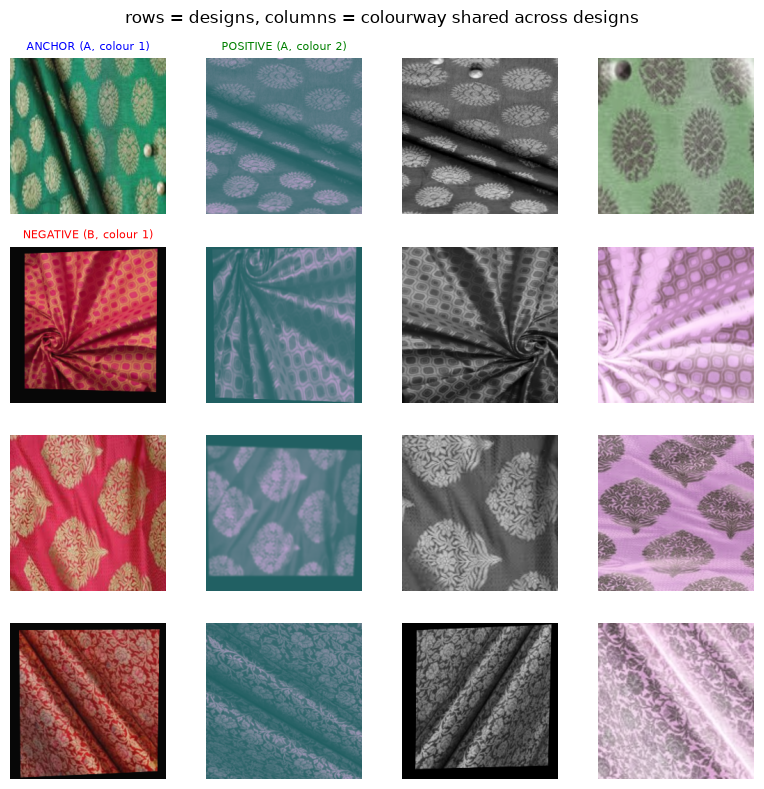

In [21]:
class PKDataset(Dataset):
    def __init__(self, dmap, K):
        self.ids = list(dmap); self.paths = [[r["path"] for r in dmap[d]] for d in self.ids]; self.K = K
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        return torch.stack([train_geo(CACHE[random.choice(self.paths[i])]) for _ in range(self.K)]), i

class PKSampler(torch.utils.data.Sampler):
    def __init__(self, n, P, iters, seed=0): self.n, self.P, self.iters, self.seed, self.epoch = n, P, iters, seed, 0
    def __len__(self): return self.iters
    def __iter__(self):
        g = random.Random(self.seed + self.epoch); self.epoch += 1
        for _ in range(self.iters):
            yield g.sample(range(self.n), min(self.P, self.n))

def colourise_batch(x, P, K, shared_prob=CFG["shared_palette_prob"]):
    dev = x.device
    shared, indep = sample_colourways(K, dev), sample_colourways(P * K, dev)
    k_idx = torch.arange(K, device=dev).repeat(P)
    use_shared = (torch.rand(K, device=dev) < shared_prob)[k_idx]
    idx = torch.where(use_shared, k_idx, K + torch.arange(P * K, device=dev))
    return apply_colourways(x, {n: torch.cat([shared[n], indep[n]])[idx] for n in shared})

train_ds = PKDataset(TRAIN, CFG["K"])
train_dl = DataLoader(train_ds, batch_sampler=PKSampler(len(train_ds), CFG["P"], CFG["iters_per_epoch"], CFG["seed"]),
                      num_workers=CFG["num_workers"], pin_memory=device.type == "cuda",
                      persistent_workers=CFG["num_workers"] > 0)

torch.manual_seed(1)
preview_ds = PKDataset(TRAIN, 4)
xb = torch.stack([preview_ds[i][0] for i in range(4)])
xc = colourise_batch(xb.flatten(0, 1), 4, 4, shared_prob=1.0).view(4, 4, 3, *xb.shape[-2:])
fig, axs = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    for c in range(4):
        axs[r, c].imshow(xc[r, c].permute(1, 2, 0)); axs[r, c].axis("off")
axs[0, 0].set_title("ANCHOR (A, colour 1)", fontsize=8, color="blue")
axs[0, 1].set_title("POSITIVE (A, colour 2)", fontsize=8, color="green")
axs[1, 0].set_title("NEGATIVE (B, colour 1)", fontsize=8, color="red")
plt.suptitle("rows = designs, columns = colourway shared across designs"); plt.tight_layout(); plt.show()



## 09. Triplet loss
Batch-hard triplet loss (Hermans et al., 2017) on L2-normalised embeddings, with $d$ = Euclidean distance:

$$\mathcal{L} = \frac{1}{N}\sum_a \big[\max_{p:\,y_p=y_a} d(a,p) - \min_{n:\,y_n\ne y_a} d(a,n) + m\big]_+ ,\quad m = 0.2$$

On unit vectors, $d^2 = 2 - 2\cos$, so this directly shapes the cosine similarity used at inference.

In [23]:
def batch_hard_triplet(emb, labels, margin=CFG["margin"]):
    d = torch.cdist(emb, emb).clamp(min=1e-12)
    same = labels[:, None] == labels[None, :]
    eye = torch.eye(len(labels), dtype=torch.bool, device=emb.device)
    hard_pos = d.masked_fill(~same | eye, 0).amax(1)
    hard_neg = d.masked_fill(same, float("inf")).amin(1)
    l = F.relu(hard_pos - hard_neg + margin)
    return l.mean(), dict(active=(l > 0).float().mean().item(), d_pos=hard_pos.mean().item(), d_neg=hard_neg.mean().item())

lab = torch.arange(4).repeat_interleave(2)
print(batch_hard_triplet(F.one_hot(lab, 8).float(), lab)[0].item(), batch_hard_triplet(F.normalize(torch.randn(8, 8), dim=1), lab)[0].item())



0.0 0.276983380317688


## 10. Training loop
AdamW (backbone lr 1e-4, head lr 1e-3), 1 warm-up epoch followed by a cosine schedule, and mixed precision on the GPU. Colourways are applied on the GPU, after the batch arrives. A checkpoint is kept every `save_every` epochs, and step 11 picks the best one on validation.

epoch  1 | loss 0.2784 | active triplets 0.98 | d(a,p) 1.296 | d(a,n) 1.219 | 319s
epoch  2 | loss 0.1539 | active triplets 0.79 | d(a,p) 1.069 | d(a,n) 1.134 | 288s
epoch  3 | loss 0.1068 | active triplets 0.60 | d(a,p) 0.940 | d(a,n) 1.080 | 310s
epoch  4 | loss 0.0762 | active triplets 0.49 | d(a,p) 0.886 | d(a,n) 1.087 | 376s
epoch  5 | loss 0.0835 | active triplets 0.48 | d(a,p) 0.867 | d(a,n) 1.073 | 364s
epoch  6 | loss 0.0621 | active triplets 0.37 | d(a,p) 0.828 | d(a,n) 1.075 | 321s
epoch  7 | loss 0.0588 | active triplets 0.38 | d(a,p) 0.812 | d(a,n) 1.069 | 446s
epoch  8 | loss 0.0599 | active triplets 0.38 | d(a,p) 0.808 | d(a,n) 1.060 | 372s
epoch  9 | loss 0.0310 | active triplets 0.26 | d(a,p) 0.772 | d(a,n) 1.085 | 327s
epoch 10 | loss 0.0448 | active triplets 0.30 | d(a,p) 0.790 | d(a,n) 1.088 | 366s
epoch 11 | loss 0.0377 | active triplets 0.27 | d(a,p) 0.772 | d(a,n) 1.091 | 349s
epoch 12 | loss 0.0408 | active triplets 0.28 | d(a,p) 0.787 | d(a,n) 1.089 | 281s
epoc

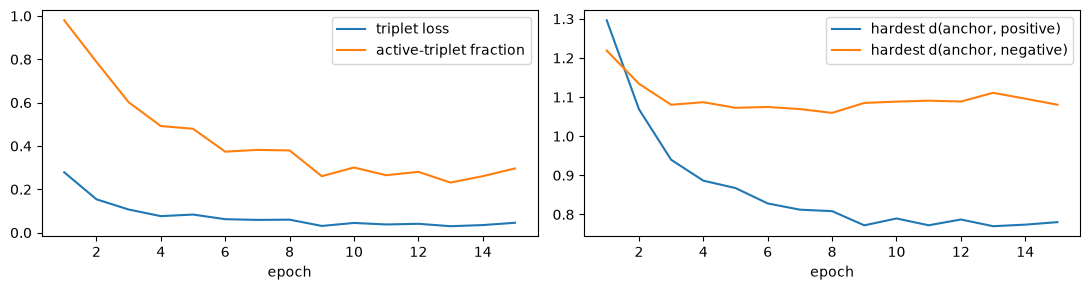

In [25]:
seed_everything(CFG["seed"])
model = SareeEncoder(CFG["embed_dim"]).to(device)
head = list(model.pool.parameters()) + list(model.proj.parameters()) + list(model.bn.parameters())
opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": CFG["lr_backbone"]},
                         {"params": head, "lr": CFG["lr_head"]}], weight_decay=CFG["weight_decay"])
total, warm = CFG["epochs"] * CFG["iters_per_epoch"], CFG["warmup_epochs"] * CFG["iters_per_epoch"]
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                          else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

history, CKPTS = [], {}
for epoch in range(1, CFG["epochs"] + 1):
    model.train(); t0, stats = time.time(), []
    for x, _ in train_dl:
        P, K = x.shape[:2]
        x = x.to(device, non_blocking=True).flatten(0, 1)
        with torch.no_grad():
            x = colourise_batch(x, P, K)
        labels = torch.arange(P, device=device).repeat_interleave(K)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            emb = model(x)
        loss, info = batch_hard_triplet(emb.float(), labels)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        stats.append([loss.item(), info["active"], info["d_pos"], info["d_neg"]])
        print(f"\repoch {epoch} | batch {len(stats)}/{CFG['iters_per_epoch']} | loss {loss.item():.4f}", end="")
    s = np.mean(stats, 0)
    history.append(dict(epoch=epoch, loss=s[0], active=s[1], d_pos=s[2], d_neg=s[3], sec=time.time() - t0))
    print(f"\repoch {epoch:2d} | loss {s[0]:.4f} | active triplets {s[1]:.2f} | d(a,p) {s[2]:.3f} | d(a,n) {s[3]:.3f} | {time.time() - t0:.0f}s")
    if epoch % CFG["save_every"] == 0 or epoch == CFG["epochs"]:
        CKPTS[epoch] = f"{OUT}/epoch{epoch:02d}.pt"
        torch.save(model.state_dict(), CKPTS[epoch])

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(h.epoch, h.loss, label="triplet loss"); ax[0].plot(h.epoch, h.active, label="active-triplet fraction"); ax[0].legend()
ax[1].plot(h.epoch, h.d_pos, label="hardest d(anchor, positive)"); ax[1].plot(h.epoch, h.d_neg, label="hardest d(anchor, negative)"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()



## 11. Validation
**Evaluation protocol.** The same protocol is used for val and test, built with a fixed seed. For each held-out design:
| set | images per design |
|---|---|
| **gallery** | original colours + 1 k-means palette swap (the gallery may hold several colourways, as the brief says) |
| **query** | 2 *other* palettes + random crop (50-100% of the area), rot90 and flip |
| **same-palette negatives** | this design and *another design of the same weave style*, both recoloured with the **identical** palette |

No query shares a palette with its own gallery entries, so only the motif can produce a match. Every checkpoint is scored on **val mAP**, and the best one is kept. The verification threshold τ is also chosen on val.

In [27]:
def _u8(x): return (x.clamp(0, 1) * 255).round().to(torch.uint8)
def random_geo(x, g):
    s = x.shape[-1]; side = int(round(s * (0.5 + 0.5 * torch.rand(1, generator=g).item()) ** 0.5))
    i, j = (torch.randint(0, s - side + 1, (2,), generator=g)).tolist()
    x = T.functional.resized_crop(x, i, j, side, side, [s, s], antialias=True)
    x = torch.rot90(x, int(torch.randint(0, 4, (1,), generator=g)), (1, 2))
    return x.flip(-1) if torch.rand(1, generator=g).item() < 0.5 else x

@torch.no_grad()
def build_eval_set(dmap, seed):
    g, rng, k = torch.Generator().manual_seed(seed), random.Random(seed), CFG["kmeans_k"]
    ids = list(dmap); G, Gl, Q, Ql, rows = [], [], [], [], []
    for li, d in enumerate(ids):
        x, xq = eval_resize(CACHE[dmap[d][0]["path"]]), eval_resize(CACHE[dmap[d][-1]["path"]])
        order, base = bool(torch.rand(1, generator=g) < 0.5), seed * 100003 + li * 7
        G += [_u8(x), _u8(kmeans_recolour(x, random_palette(k, g), base + 1, preserve_order=order))]
        rows += [(d, "c0", "gallery"), (d, f"k{base + 1}", "gallery")]
        for t in (2, 3):
            Q.append(_u8(random_geo(kmeans_recolour(xq, random_palette(k, g), base + t, preserve_order=order), g)))
            rows.append((d, f"k{base + t}", "query"))
        Gl += [li, li]; Ql += [li, li]
    by_style = defaultdict(list)
    for li, d in enumerate(ids): by_style[dmap[d][0]["style"]].append(li)
    A, B = [], []
    for li, d in enumerate(ids):
        pool = [j for j in by_style[dmap[d][0]["style"]] if j != li] or [j for j in range(len(ids)) if j != li]
        for rep in range(2):
            lj, pal, s = rng.choice(pool), random_palette(k, g), seed * 7919 + li * 13 + rep
            A.append(_u8(kmeans_recolour(eval_resize(CACHE[dmap[d][0]["path"]]), pal, s)))
            B.append(_u8(random_geo(kmeans_recolour(eval_resize(CACHE[dmap[ids[lj]][0]["path"]]), pal, s + 1), g)))
    return dict(ids=ids, gallery=torch.stack(G), g_lab=torch.tensor(Gl), query=torch.stack(Q), q_lab=torch.tensor(Ql),
                q_src=np.array([dmap[ids[l]][0]["source"] for l in Ql]), sp_a=torch.stack(A), sp_b=torch.stack(B),
                table=pd.DataFrame(rows, columns=["design_id", "colourway_id", "role"]))

@torch.no_grad()
def embed(m, X_u8, bs=64, tta_flip=True):
    m.eval(); out = []
    for i in range(0, len(X_u8), bs):
        x = X_u8[i:i + bs].to(device).float() / 255.0
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            e = m(x).float() + (m(x.flip(-1)).float() if tta_flip else 0)
        out.append(F.normalize(e, dim=1).cpu())
    return torch.cat(out)

def identification(q, g, q_lab, g_lab):
    sim = q @ g.T; order = sim.argsort(1, descending=True)
    match = (g_lab[order] == q_lab[:, None]).float(); first = match.argmax(1)
    ap = (match.cumsum(1) / torch.arange(1, match.shape[1] + 1) * match).sum(1) / match.sum(1)
    return dict(R1=(first < 1).float().mean().item(), R5=(first < 5).float().mean().item(), mAP=ap.mean().item()), sim, order

def verification(q, g, a, b, q_lab, g_lab, thr=None, seed=0):
    sim = q @ g.T; same = q_lab[:, None] == g_lab[None, :]
    pos = sim[same]
    neg_idx = np.argwhere(~same.numpy())
    pick = np.random.default_rng(seed).choice(len(neg_idx), min(len(neg_idx), 2 * len(pos)), replace=False)
    rand_neg, sp_neg = sim[neg_idx[pick, 0], neg_idx[pick, 1]], (a * b).sum(1)
    neg = torch.cat([sp_neg, rand_neg])
    y, s = np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos.numpy(), neg.numpy()]
    fpr, tpr, th = roc_curve(y, s); e = np.nanargmin(np.abs(1 - tpr - fpr))
    if thr is None: thr = float(min(th[np.argmax(tpr - fpr)], 1.0))
    r = dict(AUC=roc_auc_score(y, s),
             AUC_same_palette=roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(sp_neg))], np.r_[pos.numpy(), sp_neg.numpy()]),
             EER=float((fpr[e] + 1 - tpr[e]) / 2), TAR_at_FAR1=float(np.interp(0.01, fpr, tpr)), threshold=thr,
             TAR=float((pos >= thr).float().mean()), FAR=float((neg >= thr).float().mean()),
             FAR_same_palette=float((sp_neg >= thr).float().mean()))
    r["bal_acc"] = 0.5 * (r["TAR"] + 1 - r["FAR"])
    return r, dict(pos=pos, sp_neg=sp_neg, rand_neg=rand_neg, fpr=fpr, tpr=tpr)

def evaluate(m, es, thr=None):
    E = {k: embed(m, es[k]) for k in ("gallery", "query", "sp_a", "sp_b")}
    r_id, sim, order = identification(E["query"], E["gallery"], es["q_lab"], es["g_lab"])
    r_ver, curves = verification(E["query"], E["gallery"], E["sp_a"], E["sp_b"], es["q_lab"], es["g_lab"], thr)
    return {**r_id, **r_ver}, dict(E=E, sim=sim, order=order, **curves)

VAL_SET = build_eval_set(VAL, CFG["eval_seed"])
TEST_SET = build_eval_set(TEST, CFG["eval_seed"] + 1)
print("val :", len(VAL_SET["gallery"]), "gallery /", len(VAL_SET["query"]), "query /", len(VAL_SET["sp_a"]), "same-palette pairs")
print("test:", len(TEST_SET["gallery"]), "gallery /", len(TEST_SET["query"]), "query /", len(TEST_SET["sp_a"]), "same-palette pairs")

val_rows = []
for ep, path in CKPTS.items():
    model.load_state_dict(torch.load(path, map_location=device))
    r, _ = evaluate(model, VAL_SET); val_rows.append(dict(epoch=ep, **r))
val_df = pd.DataFrame(val_rows).set_index("epoch")
best_epoch = int(val_df.mAP.idxmax())
model.load_state_dict(torch.load(CKPTS[best_epoch], map_location=device))
torch.save(model.state_dict(), f"{OUT}/best_model.pt")
VAL_RESULT, _ = evaluate(model, VAL_SET)
THRESHOLD = VAL_RESULT["threshold"]
print(f"best epoch on val mAP: {best_epoch} | verification threshold tau = {THRESHOLD:.3f}")
val_df[["R1", "R5", "mAP", "AUC", "AUC_same_palette", "EER"]].round(4)



val : 106 gallery / 106 query / 106 same-palette pairs
test: 378 gallery / 378 query / 378 same-palette pairs
best epoch on val mAP: 15 | verification threshold tau = 0.491


,R1,R5,mAP,AUC,AUC_same_palette,EER
epoch,,,,,,
3,0.7830,0.9434,0.7569,0.9682,0.9502,0.0835
6,0.8396,0.9717,0.7714,0.9629,0.9477,0.0995
9,0.8302,0.9717,0.8132,0.9763,0.9667,0.0755
12,0.8491,0.9717,0.8158,0.9765,0.9675,0.0703
15,0.8491,0.9811,0.8245,0.9782,0.9686,0.0651


## 12. Generate gallery embeddings
The test gallery holds 2 colourways per design. Embeddings are 256-D, L2-normalised, averaged with the flipped image, and saved to disk together with their `design_id`/`colourway_id`.

In [29]:
gallery_emb = embed(model, TEST_SET["gallery"])
query_emb = embed(model, TEST_SET["query"])
tab = TEST_SET["table"]
tab.to_csv(f"{OUT}/eval_pairs_test.csv", index=False)
torch.save(dict(emb=gallery_emb, design_id=tab[tab.role == "gallery"].design_id.tolist(),
                colourway_id=tab[tab.role == "gallery"].colourway_id.tolist()), f"{OUT}/gallery_embeddings.pt")
print("gallery:", tuple(gallery_emb.shape), "| query:", tuple(query_emb.shape), "| norms:", gallery_emb.norm(dim=1)[:3])
tab.head(6)



gallery: (378, 256) | query: (378, 256) | norms: tensor([1.0000, 1.0000, 1.0000])


,design_id,colourway_id,role
0,D0354,c0,gallery
1,D0354,k123503706,gallery
2,D0354,k123503707,query
3,D0354,k123503708,query
4,D0355,c0,gallery
5,D0355,k123503713,gallery


## 13. Query → cosine similarity
The embeddings are unit vectors, so cosine similarity is just `query @ galleryᵀ`. Sorting each row gives the ranked gallery, and the Top-K **designs** are found by taking the max over each design's colourways.

In [31]:
sim = query_emb @ gallery_emb.T
order = sim.argsort(1, descending=True)
g_design = np.array(tab[tab.role == "gallery"].design_id); q_design = np.array(tab[tab.role == "query"].design_id)

def topk_designs(qi, k=5):
    best = {}
    for gi in order[qi].tolist():
        d = g_design[gi]
        if d not in best: best[d] = round(sim[qi, gi].item(), 3)
        if len(best) == k: break
    return list(best.items())

for qi in [0, 1, len(q_design) // 2]:
    print(f"query {qi} (true design {q_design[qi]}) ->", topk_designs(qi))


query 0 (true design D0354) -> [('D0354', 0.906), ('D0407', 0.618), ('D0514', 0.367), ('D0357', 0.326), ('D0530', 0.285)]
query 1 (true design D0354) -> [('D0354', 0.928), ('D0407', 0.466), ('D0514', 0.412), ('D0439', 0.29), ('D0357', 0.289)]
query 189 (true design D0477) -> [('D0529', 0.846), ('D0477', 0.816), ('D0419', 0.759), ('D0565', 0.757), ('D0467', 0.757)]


## 14. Identification metrics (Recall@1, Recall@5, mAP)
Two reference points are run on the identical protocol:
* **RGB histogram**: a pure colour descriptor. It shows what colour shortcuts score, and it fails by design.
* **ImageNet ResNet34 with no training**: shows what triplet training with colourways adds.

In [33]:
class ColourHistogram(nn.Module):
    def forward(self, x, b=8):
        q = (x.clamp(0, 1 - 1e-6) * b).long(); idx = ((q[:, 0] * b + q[:, 1]) * b + q[:, 2]).flatten(1)
        h = torch.zeros(len(x), b ** 3, device=x.device).scatter_add_(1, idx, torch.ones_like(idx, dtype=torch.float))
        return F.normalize(h.sqrt(), dim=1)

class ImageNetResNet34(nn.Module):
    def __init__(self):
        super().__init__()
        self.r = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1); self.r.fc = nn.Identity()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return F.normalize(self.r((x - self.mean) / self.std), dim=1)

RESULTS, OUTS = {}, {}
for name, m in [("RGB colour histogram", ColourHistogram()), ("ImageNet ResNet34 (no training)", ImageNetResNet34()),
                ("Ours: ResNet34 + triplet + colourways", model)]:
    m = m.to(device)
    thr = THRESHOLD if m is model else evaluate(m, VAL_SET)[0]["threshold"]
    RESULTS[name], OUTS[name] = evaluate(m, TEST_SET, thr)
    for src in ("roboflow", "deeplure"):
        msk = torch.from_numpy(TEST_SET["q_src"] == src)
        if msk.any():
            E = OUTS[name]["E"]
            r, _, _ = identification(E["query"][msk], E["gallery"], TEST_SET["q_lab"][msk], TEST_SET["g_lab"])
            RESULTS[name].update({f"{k} [{src}]": v for k, v in r.items()})
res = pd.DataFrame(RESULTS).T
res[[c for c in res.columns if c.split(" ")[0] in ("R1", "R5", "mAP")]].round(4)


,R1,R5,mAP,R1 [roboflow],R5 [roboflow],mAP [roboflow],R1 [deeplure],R5 [deeplure],mAP [deeplure]
RGB colour histogram,0.0106,0.0476,0.0262,0.00,0.10,0.0405,0.0122,0.0396,0.0240
ImageNet ResNet34 (no training),0.2619,0.4815,0.2341,0.72,0.86,0.6561,0.1921,0.4238,0.1697
Ours: ResNet34 + triplet + colourways,0.4762,0.7434,0.4077,0.98,1.00,0.8899,0.3994,0.7043,0.3342


## 15. Verification (ROC-AUC, EER, threshold)
Positives are same-design pairs across colourways. Negatives are (a) **different designs with the identical palette** and (b) random different designs. τ is fixed on validation and applied unchanged to test.

,AUC,AUC_same_palette,EER,TAR_at_FAR1,threshold,TAR,FAR,FAR_same_palette,bal_acc
RGB colour histogram,0.4214,0.0002,0.5405,0.0000,1.0000,0.0000,0.0000,0.0000,0.5000
ImageNet ResNet34 (no training),0.6863,0.5150,0.3530,0.0767,0.7193,0.6138,0.3037,0.5952,0.6550
Ours: ResNet34 + triplet + colourways,0.9003,0.8534,0.1938,0.3267,0.4912,0.8360,0.2148,0.3280,0.8106


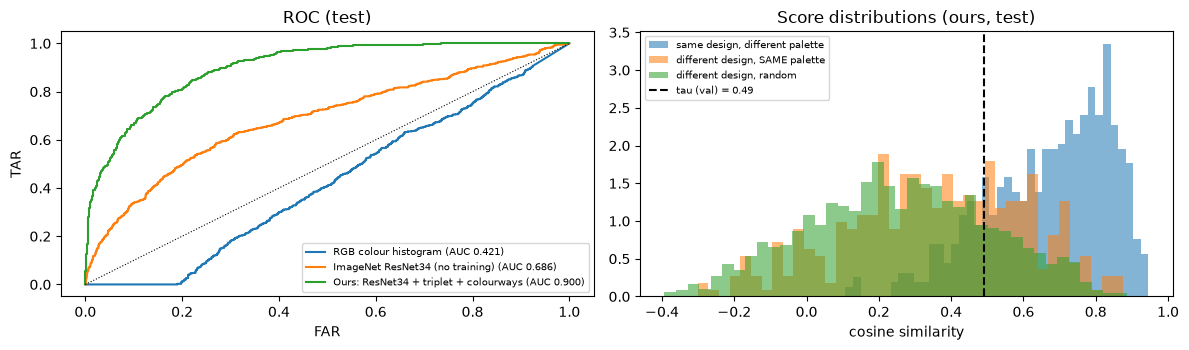

In [35]:
cols = ["AUC", "AUC_same_palette", "EER", "TAR_at_FAR1", "threshold", "TAR", "FAR", "FAR_same_palette", "bal_acc"]
display(res[cols].round(4))

o = OUTS["Ours: ResNet34 + triplet + colourways"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name, oo in OUTS.items():
    ax[0].plot(oo["fpr"], oo["tpr"], label=f"{name} (AUC {RESULTS[name]['AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8); ax[0].set_xlabel("FAR"); ax[0].set_ylabel("TAR"); ax[0].legend(fontsize=7); ax[0].set_title("ROC (test)")
kw = dict(bins=40, alpha=0.55, density=True)
ax[1].hist(o["pos"].numpy(), label="same design, different palette", **kw)
ax[1].hist(o["sp_neg"].numpy(), label="different design, SAME palette", **kw)
ax[1].hist(o["rand_neg"].numpy(), label="different design, random", **kw)
ax[1].axvline(THRESHOLD, color="k", ls="--", label=f"tau (val) = {THRESHOLD:.2f}")
ax[1].set_xlabel("cosine similarity"); ax[1].legend(fontsize=7); ax[1].set_title("Score distributions (ours, test)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_verification.png", dpi=100); plt.show()

## 16. Visualize retrieval examples
Blue is the query. Green means the same design, red means a different design. The number above each image is the cosine similarity.

In [37]:
def show_retrieval(oo, n=6, k=5, seed=0):
    qs = torch.randperm(len(TEST_SET["query"]), generator=torch.Generator().manual_seed(seed))[:n].tolist()
    fig, axs = plt.subplots(n, k + 1, figsize=(2 * (k + 1), 2 * n))
    for r, qi in enumerate(qs):
        axs[r, 0].imshow(TEST_SET["query"][qi].permute(1, 2, 0)); axs[r, 0].set_title("query", color="blue", fontsize=8)
        for c in range(k):
            gi = oo["order"][qi, c].item(); ok = TEST_SET["g_lab"][gi] == TEST_SET["q_lab"][qi]
            axs[r, c + 1].imshow(TEST_SET["gallery"][gi].permute(1, 2, 0))
            axs[r, c + 1].set_title(f"{oo['sim'][qi, gi]:.2f}", color="green" if ok else "red", fontsize=8)
            for s in axs[r, c + 1].spines.values(): s.set_edgecolor("green" if ok else "red"); s.set_linewidth(3)
        for a in axs[r]: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_retrieval.png", dpi=100); plt.show()

show_retrieval(o)

[figure removed from the public copy: it shows proprietary DeepLure images - it renders when you run the notebook]


## 17. Final results + conclusion

In [39]:
from torch.utils.flop_counter import FlopCounterMode
@torch.no_grad()
def latency_ms(m, dev, bs=1, iters=30, amp=False):
    m = m.to(dev).eval(); x = torch.rand(bs, 3, 224, 224, device=dev)
    for _ in range(5): m(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(iters):
        with torch.autocast(device_type=dev.type, enabled=amp and dev.type == "cuda"): m(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / iters * 1000

with FlopCounterMode(display=False) as fc, torch.no_grad():
    model.eval()(torch.rand(1, 3, 224, 224, device=device))
EFF = {"parameters (M)": sum(p.numel() for p in model.parameters()) / 1e6,
       "GFLOPs @224 (=2xGMACs)": fc.get_total_flops() / 1e9,
       "embedding": f"{CFG['embed_dim']}-D, {CFG['embed_dim'] * 4} B fp32 / {CFG['embed_dim'] * 2} B fp16",
       "CPU latency bs=1 (ms)": latency_ms(model, torch.device("cpu"))}
if device.type == "cuda":
    EFF["GPU latency bs=1 fp16 (ms)"] = latency_ms(model, device, amp=True)
    EFF["GPU throughput bs=64 fp16 (img/s)"] = 64 / latency_ms(model, device, bs=64, amp=True) * 1000
model.to(device)
display(pd.Series(EFF, name="efficiency").to_frame())

final = res[["R1", "R5", "mAP", "AUC", "AUC_same_palette", "EER", "TAR_at_FAR1", "bal_acc", "FAR_same_palette"]].round(4)
final.to_csv(f"{OUT}/final_results.csv")
json.dump(dict(cfg=CFG, best_epoch=best_epoch, threshold=THRESHOLD, test=RESULTS, efficiency=EFF),
          open(f"{OUT}/results.json", "w"), indent=1, default=float)
final


,efficiency
parameters (M),21.416257
GFLOPs @224 (=2xGMACs),7.326761
embedding,"256-D, 1024 B fp32 / 512 B fp16"
CPU latency bs=1 (ms),142.740653


,R1,R5,mAP,AUC,AUC_same_palette,EER,TAR_at_FAR1,bal_acc,FAR_same_palette
RGB colour histogram,0.0106,0.0476,0.0262,0.4214,0.0002,0.5405,0.0000,0.5000,0.0000
ImageNet ResNet34 (no training),0.2619,0.4815,0.2341,0.6863,0.5150,0.3530,0.0767,0.6550,0.5952
Ours: ResNet34 + triplet + colourways,0.4762,0.7434,0.4077,0.9003,0.8534,0.1938,0.3267,0.8106,0.3280


In [41]:
@torch.no_grad()
def embed_file(path):
    return embed(model, _u8(eval_resize(load_square(path)))[None])[0]

def identify(path, k=5):
    s = gallery_emb @ embed_file(path)
    best = {}
    for gi in s.argsort(descending=True).tolist():
        best.setdefault(g_design[gi], round(s[gi].item(), 3))
        if len(best) == k: break
    return list(best.items())

def verify(path_a, path_b):
    s = float(embed_file(path_a) @ embed_file(path_b))
    return s >= THRESHOLD, round(s, 3)

p0 = TEST[TEST_SET["ids"][0]][0]["path"]
print("identify:", identify(p0, 3), "| true:", TEST_SET["ids"][0])
print("verify same image:", verify(p0, p0))


identify: [('D0354', 1.0), ('D0407', 0.462), ('D0439', 0.371)] | true: D0354
verify same image: (True, 1.0)


### Conclusion
* **Formulation.** Saree recognition is treated as open-set metric learning, like face recognition: a 256-D colour-invariant embedding plus cosine similarity. It serves both **identification** (ranking against the gallery) and **verification** (cosine ≥ τ). New designs and new garment categories can be added to the gallery without retraining.
* **Why it works.** Positives always differ in colour, so colour can never be the cue. Shared palettes put *identical-colour, different-motif* negatives in every batch, so the model also cannot ignore the motif. Both halves of the core requirement are therefore built into the loss.
* **Rigour.** The evaluation designs are unseen and deduplicated at the photo level. The test recolouring operator is held out from training. Same-palette negatives are measured separately. τ is chosen on val only. Colour-histogram and ImageNet baselines are run on the identical protocol.
* **Limitations and next steps.** The colourways are synthetic, and the most valuable next step is a small set of *real* multi-colourway SKUs for validation. Each design has only one photo, so viewpoint invariance comes from crops alone. The test set is small (189 designs). Ideas not yet tried: a luminance-only input stem (colour invariance by construction), a lighter backbone (MobileNetV3 or ResNet18), and int8 embeddings.
* **Disclosures.** Pretrained torchvision `ResNet34_Weights.IMAGENET1K_V1`. Data: Kaggle *Indian Saree Patterns* (Roboflow, MIT) and the DeepLure corpus (proprietary). The DeepLure corpus is not redistributed and will be deleted after the exercise. No external data.